# **1. Atividade guiada em Colab – Controle fuzzy de ventilador**
*Cenário:*
Controlar a *velocidade de um ventilador* com base em duas entradas:

 - Temperatura do ambiente (°C)
 - Umidade relativa (%)

Saída:

 - Velocidade do ventilador (0–100%)

**Passo 0 – Setup no Colab**



In [ ]:
#Instalar scikit-fuzzy (rodar uma vez no Colab)
!pip install scikit-fuzzy

import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 10.5 MB/s eta 0:00:00


*Anotações:*

- ctrl é o módulo específico para **sistemas de controle fuzzy**.

- Vamos montar todo o fluxo: entradas → regras → saída → simulação.
---
**Passo 1 – Definir variáveis (universos de discurso)**


In [ ]:
# Universos de discurso
temp = ctrl.Antecedent(np.arange(15, 41, 1), 'temperatura')   # 15 a 40 °C
umid = ctrl.Antecedent(np.arange(20, 101, 1), 'umidade')      # 20 a 100 %
vent = ctrl.Consequent(np.arange(0, 101, 1), 'ventilador')    # 0 a 100 %


*Anotações:*

- `Antecedent:` entradas (sensores).
- `Consequent:` saída (atuador).
- Faixas escolhidas para um cenário realista de conforto térmico.

---
**Passo 2 – Definir funções de pertinência**

In [ ]:
# Temperatura: fria, agradável, quente
temp['fria']       = fuzz.trimf(temp.universe, [15, 15, 25])
temp['agradavel']  = fuzz.trimf(temp.universe, [20, 25, 30])
temp['quente']     = fuzz.trimf(temp.universe, [27, 40, 40])

# Umidade: baixa, media, alta
umid['baixa'] = fuzz.trimf(umid.universe, [20, 20, 50])
umid['media'] = fuzz.trimf(umid.universe, [40, 60, 80])
umid['alta']  = fuzz.trimf(umid.universe, [70, 100, 100])

# Ventilador: baixo, medio, alto
vent['baixo'] = fuzz.trimf(vent.universe, [0, 0, 40])
vent['medio'] = fuzz.trimf(vent.universe, [20, 50, 80])
vent['alto']  = fuzz.trimf(vent.universe, [60, 100, 100])


*Anotações:*

- Triangulares para simplicidade e boa interpretabilidade.

- Sobreposição garante transição suave entre estados.

---
**Passo 3 – Visualizar funções (opcional mas didático)**

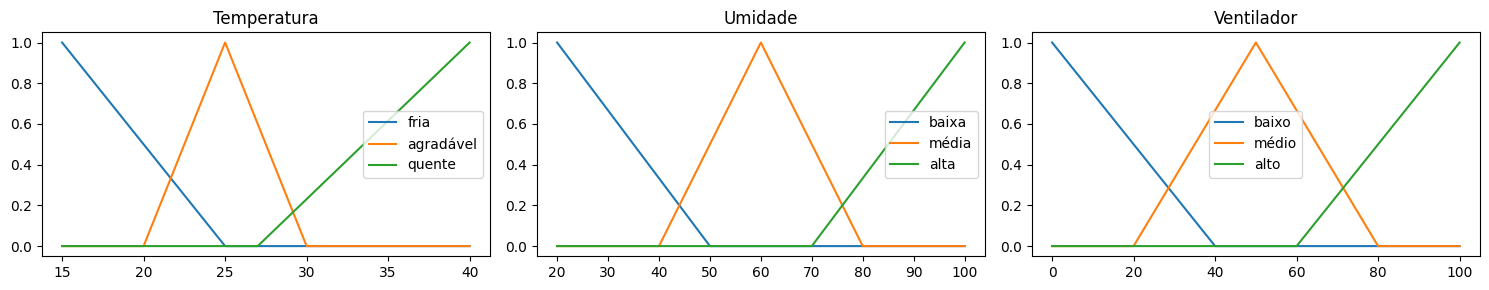

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3))
# Temperatura
axs[0].plot(temp.universe, temp['fria'].mf, label='fria')
axs[0].plot(temp.universe, temp['agradavel'].mf, label='agradável')
axs[0].plot(temp.universe, temp['quente'].mf, label='quente')
axs[0].set_title('Temperatura')
axs[0].legend()
# Umidade
axs[1].plot(umid.universe, umid['baixa'].mf, label='baixa')
axs[1].plot(umid.universe, umid['media'].mf, label='média')
axs[1].plot(umid.universe, umid['alta'].mf, label='alta')
axs[1].set_title('Umidade')
axs[1].legend()
# Ventilador
axs[2].plot(vent.universe, vent['baixo'].mf, label='baixo')
axs[2].plot(vent.universe, vent['medio'].mf, label='médio')
axs[2].plot(vent.universe, vent['alto'].mf, label='alto')
axs[2].set_title('Ventilador')
axs[2].legend()

plt.tight_layout()
plt.show()


*Anotações:*

- Interpretar onde a pertinência é alta/baixa.

- Explore “zonas de ambiguidade” (interseções).
---
**Passo 4 – Definir regras fuzzy**

In [ ]:
# Regras
regra1 = ctrl.Rule(temp['fria'] & umid['baixa'], vent['baixo'])
regra2 = ctrl.Rule(temp['fria'] & umid['alta'],  vent['medio'])

regra3 = ctrl.Rule(temp['agradavel'] & umid['baixa'], vent['medio'])
regra4 = ctrl.Rule(temp['agradavel'] & umid['media'], vent['medio'])
regra5 = ctrl.Rule(temp['agradavel'] & umid['alta'],  vent['alto'])

regra6 = ctrl.Rule(temp['quente'] & umid['baixa'], vent['medio'])
regra7 = ctrl.Rule(temp['quente'] & umid['media'], vent['alto'])
regra8 = ctrl.Rule(temp['quente'] & umid['alta'],  vent['alto'])


*Anotações:*

- Regras simulam raciocínio humano:

  - Se está quente e úmido, ventilador alto.

  - Se está frio e seco, ventilador baixo, etc.

- Discuta se os alunos mudariam alguma regra.
---

**Passo 5 – Criar sistema de controle e simular**

Velocidade do ventilador (saída crisp): 82.38095238095238


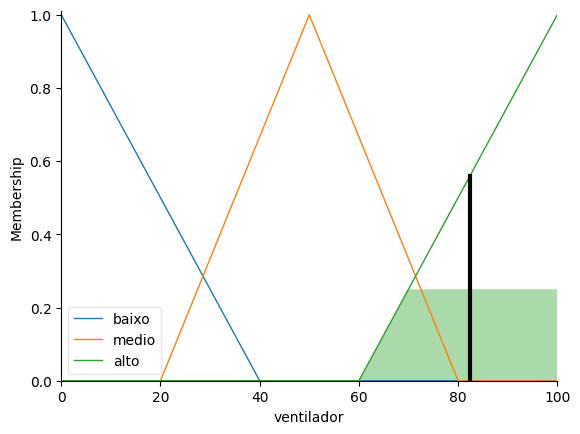

In [ ]:
# Sistema de controle
vent_ctrl = ctrl.ControlSystem([regra1, regra2, regra3, regra4, regra5, regra6, regra7, regra8])
sim = ctrl.ControlSystemSimulation(vent_ctrl)

# Exemplo de entrada: 32 °C, 75% umidade
sim.input['temperatura'] = 32
sim.input['umidade'] = 75

# Computar saída
sim.compute()

print("Velocidade do ventilador (saída crisp):", sim.output['ventilador'])

# Visualizar saída
vent.view(sim=sim)
plt.show()


*Anotações:*

- sim.input[...] configura a situação atual.

- sim.compute() faz fuzzificação → inferência → defuzzificação.

- vent.view(sim=sim) mostra graficamente qual região foi ativada.

---
Tarefa para Testar (dentro da atividade)
- Mudar um cenário: por exemplo, temp=22, umid=40.
- Observar como a saída muda.
- Modificar uma regra e comparem os resultados (explicar o efeito).